# This script is for creating the biophysical model and running some analyses of the simulations

In [1]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot, Polynomials

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
include("run_sim.jl")
include("conv_spikes_rates.jl") 

┌ Warning: Error requiring `MakieCore` from `Polynomials`
│   exception = (LoadError("/Users/nmt121/.julia/packages/Polynomials/6i39P/ext/PolynomialsMakieCoreExt.jl", 1, ArgumentError("Package Polynomials does not have MakieCore in its dependencies:\n- If you have Polynomials checked out for development and have\n  added MakieCore as a dependency but haven't updated your primary\n  environment's manifest file, try `Pkg.resolve()`.\n- Otherwise you may need to report an issue with Polynomials")), Union{Ptr{Nothing}, Base.InterpreterIP}[Ptr{Nothing} @0x000000010f1e951e, Ptr{Nothing} @0x000000010d5649bf, Ptr{Nothing} @0x000000010d595a0c, Ptr{Nothing} @0x000000010d594e62, Ptr{Nothing} @0x000000010d594a65, Ptr{Nothing} @0x000000010d595104, Ptr{Nothing} @0x000000010d595c34, Ptr{Nothing} @0x0000000122737d67, Ptr{Nothing} @0x000000010d5649bf, Ptr{Nothing} @0x000000012262828a, Ptr{Nothing} @0x0000000122627d62, Ptr{Nothing} @0x000000010d5649bf, Ptr{Nothing} @0x000000010d571259, Ptr{Nothing} @0x0

conv_spikes_rates (generic function with 1 method)

## MN parameters 

### Slow-type motoneurons

In [2]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87

# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_VL_7sept.jld2" VthCa_newVL
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_TA_6sept.jld2" VthCa_newTA

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_newTA[1,:] # vcat(LinRange(2.5,3.,nr_s)) # VthCa_newTA[1,:]
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion
# IF= zeros(nr_s) 

# max_val= maximum(VthCa_newTA[1,:])
# min_val= minimum(VthCa_newTA[1,:])

# for i in 1:length(VthCa_newTA[1,:])
#           IF[i] = (1- (VthCa_newTA[1,i] - min_val) / (max_val - min_val))*0.8
# end
#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 


### Different excitatory profiles to understand some effects of PICs such as facilitation

In [20]:
# flat_length = 20000
# remaining_length = sim_length - flat_length
# edge_length = div(remaining_length, 2)
# flat = fill(amplitude, flat_length)
# up = range(0, stop = amplitude, length = edge_length + 1)
# down = range(amplitude, stop = 0, length = edge_length + 1)
# tr = vcat(up[2:end], flat, down[2:end])
# Plots.plot(tr)

In [3]:
# ########### SINUSOID ############
# # frequency = 3 

# # x_values = range(0, stop=frequency*2π, length=sim_length)
# # tr = (amplitude / 2) * sin.(x_values .- π/2) .+ (amplitude / 2)
# sim_length=5000
# frequency = 0.25     # Frequency in Hz
# amplitude_min = 0.16
# amplitude_max = 0.4
# duration = 5      # Duration in seconds

# # Time array
# t = range(0, stop=duration, length=sim_length)

# # Generate the sinusoidal signal with a frequency of 3 Hz
# x_values = 2 * π * frequency * t
# signal = sin.(x_values .- π/2)  # Adjust phase to start at minimum

# # Scale the signal to range from 0.16 to 0.4
# signal = (signal .+ 1) / 2  # Normalize to range [0, 1]
# tr = signal * (amplitude_max - amplitude_min) .+ amplitude_min  # Scale to range [0.16, 0.4]


# # Plot the trajectory
# Plots.plot(x_values, tr, label="Trajectory", legend=false, linewidth=6, color=:blue, grid=false)


In [3]:
# ############ CHRIP ############

# sim_length=10000
# duration = 10.0  # Duration in seconds
# points = 10000   # Number of points in the x-axis
# f0 = 0           # Starting frequency
# f1 = 3.0         # Ending frequency
# amplitude_min = 0.25
# amplitude_max = 1

# t = range(0, stop=duration, length=points)
# phase = 2 * π * (f0 .+ (f1 - f0) .* t / duration) .* t
# signal = sin.(phase .- π/2)  # Adjust phase to start at minimum
# signal = (signal .+ 1) / 2  # Normalize to range [0, 1]
# tr = signal * (amplitude_max - amplitude_min) .+ amplitude_min  # Scale to range [0.16, 0.4]
# tr[1] = amplitude_min
# tr[end] = amplitude_min

# Plots.plot(t, tr, label="Chirp Signal", legend=false, linewidth=2, color=:blue, grid=false)


### Use the next line if you want to plot how much flexibility your neurons have (i.e.: after using the controller)

In [1]:
# Plots.scatter([2,6],[-67,19],grid=false, xlim=(0.1,8),ylim=(-80,30),color=:springgreen3,markerstrokecolor=:springgreen3, legend=false,markersize = 10)

### MN parameters we need to fill with previous data (and creation of the dictionary)

In [3]:
ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV ohms law
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;

### Running simulation

In [4]:
tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function

#### Different profiles of inhibition

In [6]:
########### PUSH-PULL ###########
# amplitude=0.4
# factor=0.4*0.8
# tr_length=30000
# half_triang = div(tr_length, 2)  

# down = range(amplitude, -0.1+factor, length = half_triang + 1)  
# up = range(-0.1+factor, amplitude, length = tr_length - half_triang + 1)  
# inh_input = vcat(down[2:end], up[2:end])
# sim_length=30000

# Plots.plot(tr,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)

In [7]:
########### BALANCED ###########

# amplitude=0.4*0.8
# tr_length=28000
# half_triang = div(tr_length, 2)  
# flat_line = fill(-0.1, 1000)
# up = range(-0.1, amplitude, length = half_triang + 1)  
# down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
# inh_input = vcat(flat_line, up[2:end], down[2:end], flat_line)
# sim_length=30000

# Plots.plot(tr,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)


In [11]:
########### CONSTANT ###########

# inh_input=fill(0.1*amplitude, sim_length); #if we are using a constant inh

# Plots.plot(commoninput,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)


### RUN SIMULATION

In [5]:
full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))

factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length); #if we are using a constant inh

# tr=tr_new
# @time spike_array, vs_array    = run_sim();

@time spike_array, vs_array,pt_arr = run_sim();


450.265342 seconds (15.94 G allocations: 265.542 GiB, 12.56% gc time, 0.01% compilation time)


In [30]:
# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/DR_Sin_NOPIcs.jld2" spike_array
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/DR_trapezoid_pic.jld2" spike_array
# MAT.matwrite("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/DR_Chirp_PIC.mat", Dict("spike_array" => spike_array)) #save for matlab

1-element Vector{Symbol}:
 :spike_array

### To plot state parameters

In [280]:
# PLOT THE STATE PARAMETERS
# fig = CairoMakie.Figure(resolution = (2000, 1000))
# rows = ceil(Int, sqrt(nr_s))
# cols = ceil(Int, nr_s / rows)
# for i in 1:nr_s
#     row = div(i - 1, cols) + 1
#     col = mod(i - 1, cols) + 1
#     ax = CairoMakie.Axis(fig[row, col])#) title = "Motoneuron $i", xlabel = "Time", ylabel = "Voltage")
#     CairoMakie.lines!(ax, vs_array[i, 1:600000], label = "Trace $i")
# end
# CairoMakie.display(fig)

### Raster plot

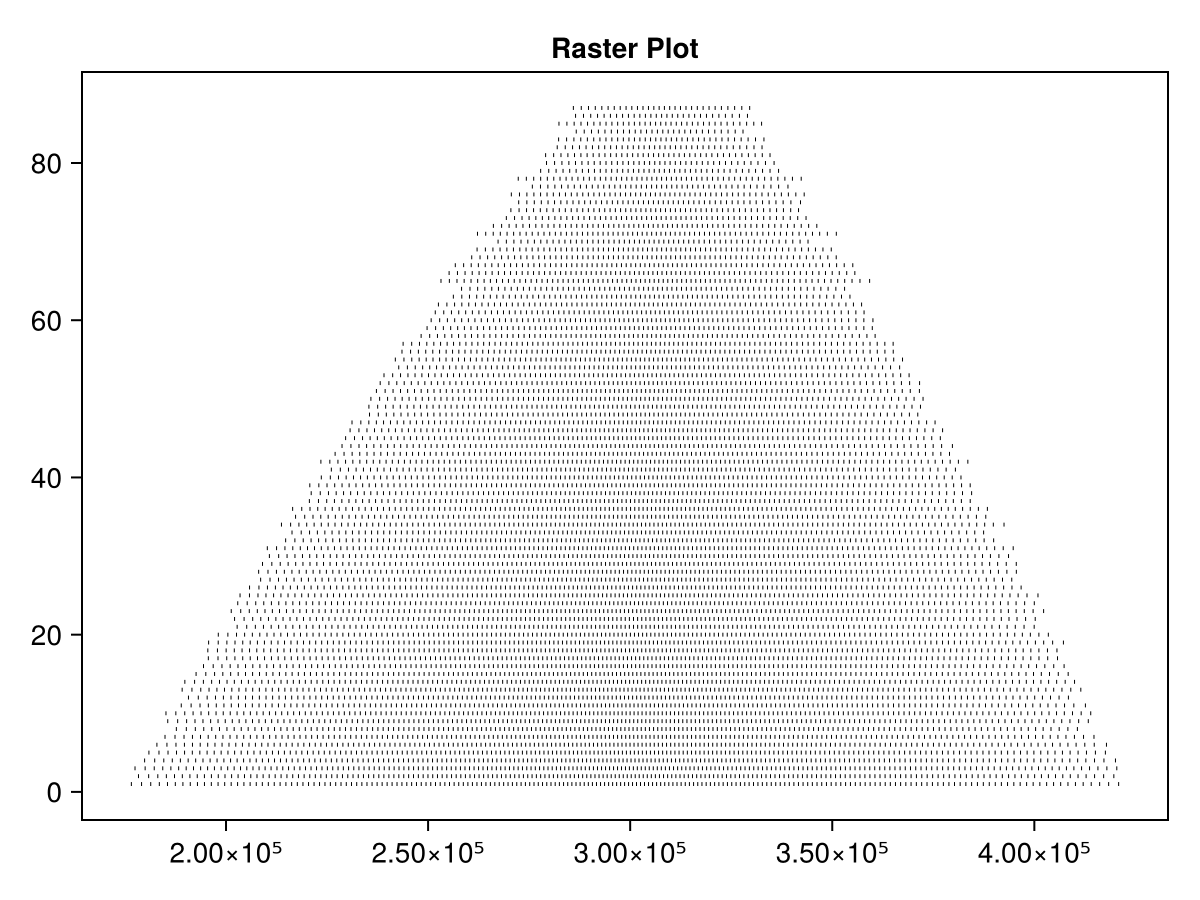

CairoMakie.Screen{IMAGE}


In [17]:
n_neurons, n_times = size(spike_array)
CairoMakie.activate!()

fig = CairoMakie.Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in 1:n_neurons
        if spike_array[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)
        end
    end
end
ax.xgridvisible = false
ax.ygridvisible = false



# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


### Plot different state spaces with the firing rate of a pair of MNs

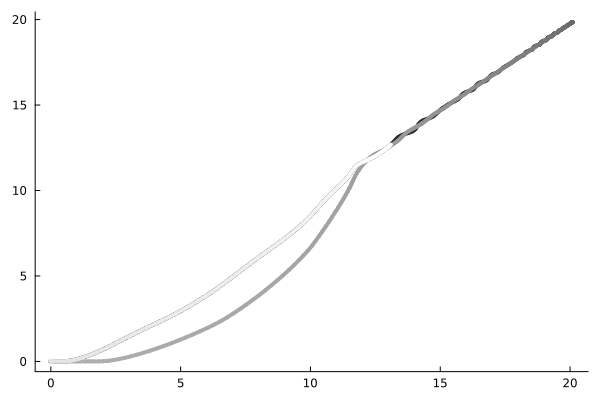

In [37]:
smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(reshape(spike_array[13,:],(1,length(spike_array[9,:]))), reshape(spike_array[14,:],(1,length(spike_array[12,:]))))
# the number that we put in length() doesn't matter, it is just for taking the length of the simulation, that is the same for all the cases
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 100
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;


color_map = [get(ColorSchemes.grays, i) for i in LinRange(0, 1, size(trajectory2_controlled, 1))]

lines_x = []
lines_y = []
colors = []

for i in 1:(size(trajectory2_controlled, 1) - 1)
    push!(lines_x, [trajectory2_controlled[i, 1], trajectory2_controlled[i + 1, 1]])
    push!(lines_y, [trajectory2_controlled[i, 2], trajectory2_controlled[i + 1, 2]])
    push!(colors, color_map[i])
end

p = Plots.plot(legend=false, grid=false)
for i in 1:length(lines_x)
    Plots.plot!(p, lines_x[i], lines_y[i], color=colors[i], linewidth=4)
end

display(p)

##### Faster way to plot for a Raster Visualitation

# W&B - Hyperparameter sweep to explore the whole range of possible values for VthCa

In [8]:
# function simulate_hh_hysteresis_constant_inh(γh::Vector,i,MN_list)    
#     MN_list[i][:γh] = γh[1]
#     MNs= MN_list[i]
#     spike_array, _ = run_sim_optim_constant_inh(i);
#     amplitude=0.4;
#     sim_length=560000 ;
#     half_triang = div(sim_length, 2);  
#     flat_line = fill(-0.1, 20000);
#     up = range(-0.1, amplitude, length = half_triang + 1)  ;
#     down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
#     tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
#     equiv_force_profile= tr
#     hysteresis= []
#     if !isempty(spike_array) && any(spike_array[1, :] .== 1)            
#         value_1= equiv_force_profile[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
#         value_2=  equiv_force_profile[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold
#         hysteresis= (value_2/value_1).-1

#     else
#         hysteresis=500 #random high value
#     end

#     max_firing_rates= [] #firing_rates_max(spike_array,i)
    
#     return hysteresis, max_firing_rates
# end


# function run_sim_optim_constant_inh(i)

#     full_input = commoninput 
#     _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
#     # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
#     spikes = spikes_from_aps(vs, i, MNs)       
#     spike_arr = reshape(spikes, 1, length(spikes))
#     vs_arr[i,:] = vs
#     return spike_arr, vs_arr
# end




# function firing_rates_max(spike_array,i)

#     max_rates_mns=[]
#     for i in 1: size(spike_array)[1]
#         spike_pos=[]
#         for j in 1:size(spike_array)[2]
#             if spike_array[i,j]==1.0
#                 push!(spike_pos,j)
#             end
#         end
#         ISI= diff(spike_pos);
#         rates= 1 ./(ISI/20000)
#         max_rates= maximum(rates)
#         max_rates_mns=max_rates
        
#     end
    
#     max_rate_mn= max_rates_mns;
    
#     return max_rate_mn;
    
#     end




In [10]:
# i = 1

# γh_range = LinRange(0., 1., 5)
# vtha_vals = LinRange(0., 5, 5)

# inh_input = []

# for j in 1:length(γh_range)
    
#     for k in 1:length(vtha_vals)

#         run_name = "gamma_h_" * string(γh_range[j]) * "vthca" * string(vtha_vals[k])

#         lg = WandbLogger(project="trial1.3", name=run_name, config=Dict("gamma_h" => γh_range[j], "vthca" => vtha_vals))


#         MN_list[i][:γh] = γh_range[j]
#         MN_list[i][:VthCa] = vtha_vals[k]

#         inh_input = fill(0.1* amplitude, sim_length)

#         hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

#         Wandb.log(lg, Dict("gamma_h" => γh_range[j], "vthca" =>vtha_vals[k] , "hysteresis" => hysteresis))

#         Wandb.close(lg)
#     end
# end



In [11]:
# Wandb.close(lg)

# Analysis of the distribution

### Computation of the hysteresis, recruitment and derecruitment threhsolds of the simulated MNs

In [6]:
#Get excitatory inputs 
amplitude=0.4;
sim_length=560000 ;
half_triang = div(sim_length, 2);  
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);

recr_inter_input= zeros(1,nr_s)
derecr_inter_input= zeros(1,nr_s)
hysteresis=zeros(1,nr_s)

for n in 1:nr_s
    if any(spike_array[n, :] .== 1)
        recr_inter_input[1,n]= tr[findfirst(==(1),spike_array[n,:]),:][1] #force at the recruitment threshold relative to the defined exc input
        derecr_inter_input[1,n]=  tr[findlast(==(1),spike_array[n,:]),:][1] #force at the derecruitment threshold
        hysteresis[1,n]= (derecr_inter_input[1,n]/recr_inter_input[1,n]).-1
    else #this is for the case in which for some reason there are no spikes for one of the neurons
        hysteresis[1,n]= NaN
    end
end

### Analyses for comparing experimental and simulated data

In [10]:
df_h = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/histogramTA_hysteresis.csv",DataFrame; header=false);
# df_hyst = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresisVL.csv",DataFrame; header=false);
hysteresis_exp = df_h[:, 1];

### Plot of the error of the optimisation process of both muscles after optimisation

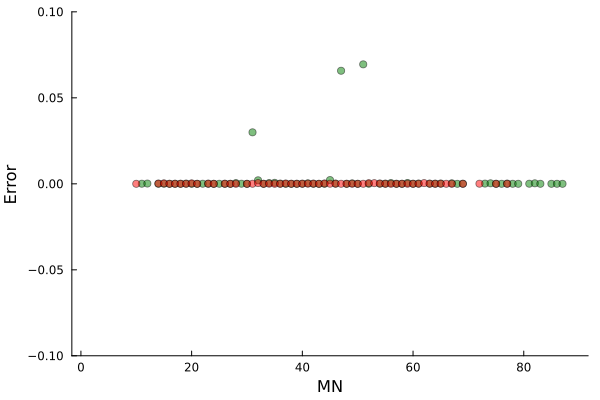

In [22]:
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_TA_6sept.jld2" sorted_minimum_values
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_TA_6sept.jld2" sorted_neuron_indices

s1= sorted_minimum_values
s11=sorted_neuron_indices

JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_VL_7sept.jld2" sorted_minimum_values
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_VL_7sept.jld2" sorted_neuron_indices

Plots.scatter(s11, s1, xlabel="MN", ylabel="Error", line=:solid,grid=false,label=false,ylim=(-0.1, 2),color=:green,alpha=0.5)
Plots.scatter!(sorted_neuron_indices, sorted_minimum_values, xlabel="MN", ylabel="Error", line=:solid,grid=false,label=false,ylim=(-0.1, 0.1),color=:red,alpha=0.5)

## Compute R2

In [16]:
# Example inputs
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_VL_7sept.jld2" sorted_minimum_values
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_VL_7sept.jld2" sorted_neuron_indices

# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_TA_6sept.jld2" sorted_minimum_values
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_TA_6sept.jld2" sorted_neuron_indices

ssd = sorted_minimum_values;

In [14]:
# Filter the data for when hysteresis_exp < 0
filtered_exp = hysteresis_exp[hysteresis_exp .< 0]
filtered_sim = hysteresis[hysteresis_exp .< 0]  # Apply the same filter to hysteresis

# Step 1: Compute the mean of the filtered experimental data
mean_exp_filtered = mean(filtered_exp)

# Step 2: Compute the total sum of squares (TSS) for the filtered data
TSS_filtered = sum((filtered_exp .- mean_exp_filtered).^2)

# Step 3: Compute the residual sum of squares (RSS) for the filtered data
RSS_filtered = sum((filtered_exp .- filtered_sim).^2)

println("Filtered TSS: ", TSS_filtered)
println("Filtered RSS: ", RSS_filtered)


Filtered TSS: 1.1670696579598492
Filtered RSS: 0.19686531897058032


In [15]:
R2 = 1 - (RSS_filtered / TSS_filtered)


0.8313165648443641

### Polynomial fittings

R^2 for Hysteresis: 0.5209517017942179


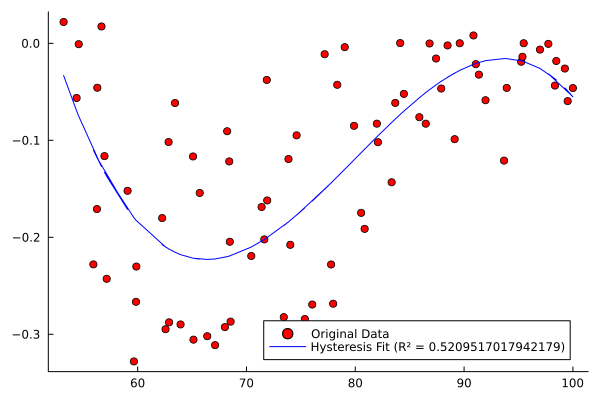

In [90]:
x = recr_inter_input / maximum(recr_inter_input) * 100
x_data = x[1,10:nr_s] 

hysteresis_s=hysteresis[1,10:nr_s]

poly_hysteresis_s = Polynomials.fit(x_data, hysteresis_s, 3)

# # Generate fitted values
y_fit_hysteresis = poly_hysteresis_s.(x_data)

ss_res_hysteresis = sum((hysteresis_s .- y_fit_hysteresis).^2)
ss_tot_hysteresis = sum((hysteresis_s .- mean(hysteresis)).^2)
r2_hysteresis = 1 - ss_res_hysteresis / ss_tot_hysteresis


# Print the R^2 values
println("R^2 for Hysteresis: ", r2_hysteresis)

# # Plot the original data and the polynomial fits
Plots.scatter(x_data, hysteresis_s, label="Original Data", color=:red,grid=false)
Plots.plot!(x_data, poly_hysteresis_s.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:blue)


R^2 for Hysteresis: 0.422060556329667


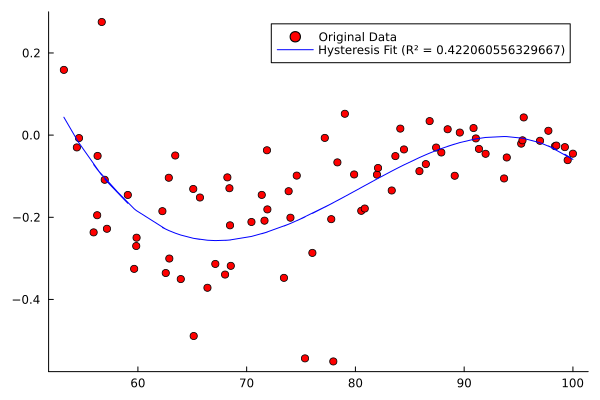

In [94]:
x = recr_inter_input / maximum(recr_inter_input) * 100
x_data = x[1,10:nr_s] 

hysteresis_e=hyst_exp[10:nr_s]

poly_hysteresis = Polynomials.fit(x_data, hysteresis_e, 3)

# # Generate fitted values
y_fit_hysteresis = poly_hysteresis.(x_data)

ss_res_hysteresis = sum((hysteresis_e .- y_fit_hysteresis).^2)
ss_tot_hysteresis = sum((hysteresis_e .- mean(hysteresis)).^2)
r2_hysteresis = 1 - ss_res_hysteresis / ss_tot_hysteresis


# Print the R^2 values
println("R^2 for Hysteresis: ", r2_hysteresis)

# # Plot the original data and the polynomial fits
Plots.scatter(x_data, hysteresis_e, label="Original Data", color=:red,grid=false)
Plots.plot!(x_data, poly_hysteresis.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:blue)


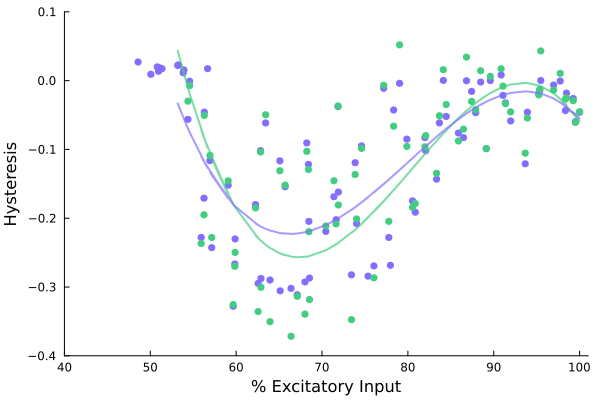

In [95]:
Plots.scatter(recr_inter_input/maximum(recr_inter_input)*100, hysteresis, grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Hysteresis",xlim=(40,101),ylim=(-.4, .5), markercolor=:slateblue1, markerstrokecolor=:slateblue1)
Plots.scatter!((recr_inter_input/maximum(recr_inter_input)*100)[1,:], hyst_exp, grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Hysteresis",xlim=(40,101),ylim=(-.4, 0.1),color=:seagreen3,markercolor=:seagreen3,markerstrokewidth=0)

Plots.plot!(x_data, poly_hysteresis.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:seagreen3,alpha=0.7,width=2)
Plots.plot!(x_data, poly_hysteresis_s.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:slateblue1,alpha=0.7,width=2)

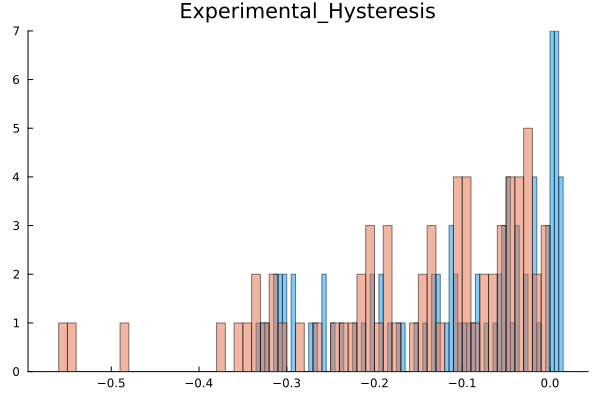

In [154]:
Plots.histogram( hysteresis[1,:],bins=100,grid=false,legend=false,title="Simulated Hysteresis",alpha=0.5)
Plots.histogram!( exp_h,bins=80,grid=false,legend=false,title="Experimental_Hysteresis",alpha=0.5)

# Computation of the rates 

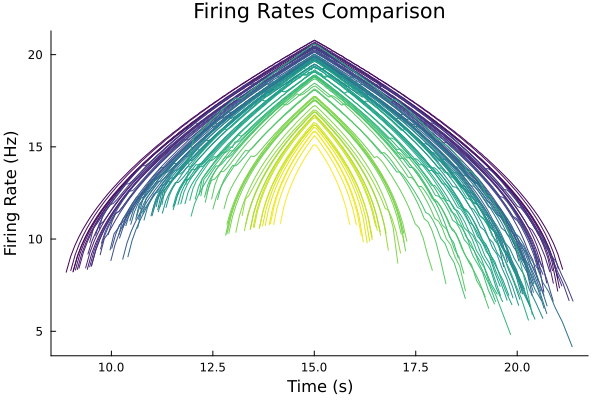

In [172]:
sampling_rate = 20000  # Hz

all_timebases = []
all_rates = []

for mn in 1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

color_map = get(ColorSchemes.viridis, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], color=color_map[i], legend=false, grid=false)
    end
end

display(p)


### following code is to make all rates the same length so then I can compare then

In [175]:
num_rows = length(all_rates)
row_lengths = [length(row) for row in all_rates]
max_length = maximum(row_lengths)

new_all_rates=zeros(nr_s,max_length)
for i in 1:nr_s
    rate_per_neuron = all_rates[i]
    v=max_length-length(rate_per_neuron)

    new_all_rates[i, :] .= vcat(rate_per_neuron,fill(NaN, v))
end


# #################################################
num_rows = length(all_timebases)
row_lengths = [length(row) for row in all_timebases]
max_length = maximum(row_lengths)

new_all_bases=zeros(nr_s,max_length)
for i in 1:nr_s
    rate_per_neuron = all_timebases[i]
    v=max_length-length(rate_per_neuron)

    new_all_bases[i, :] .= vcat(rate_per_neuron,fill(NaN, v))
end


In [179]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/allratesVL.jld2" new_all_rates
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/alltimebasesVL.jld2" new_all_bases


### Plot of recruitment threshold VS. max firing rates per motoneuron - they should follow a linear decrease

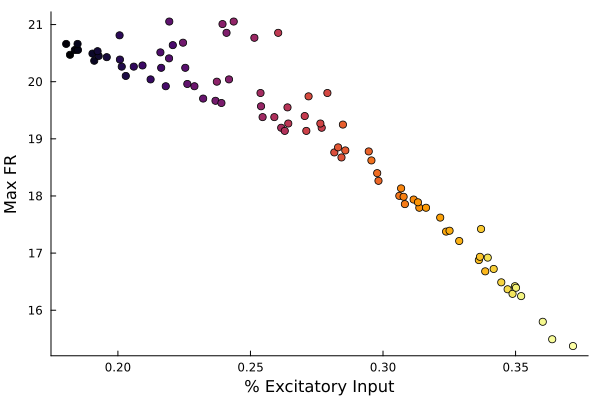

In [25]:
max_vals=zeros(1,nr_s)
color_map = get(ColorSchemes.inferno, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false)

for i in 1:nr_s
    if !isempty(all_rates[i])
        max_vals[1,i]=maximum(all_rates[i])
        Plots.scatter!([recr_inter_input[i]], [max_vals[1,i]],color=color_map[i], grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Max FR")#,ylim=(-0.5, 0.5))
    end
end
# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/max_fr_VCa_m3.jld2" max_vals
display(p)

# Checking motoneuron similarity for the controller 

##### Find motoneurons that have the most similar recruitment thresholds

In [26]:
mn_that_is_similar = [Int[] for _ in 1:nr_s]

for i in 1:nr_s

    diff = zeros(Float64, nr_s)

    for j in 1:nr_s
        if i==j #do not compare the MN with itself
            diff[j] = NaN
        else
            diff[j] = abs(recr_inter_input[i] - recr_inter_input[j]) #compare recruitment threshold 
        end
    end

    min_diff = minimum(filter(!isnan, diff)) #find the minimum difference between recruitment thresholds of motoneurons 
    
    mn_that_is_similar[i] = findall(x -> x == min_diff, diff)   # find the most similar mn

end
mn_that_is_similar

87-element Vector{Vector{Int64}}:
 [2]
 [1]
 [5]
 [5]
 [4]
 [7]
 [6]
 [9]
 [8]
 [8]
 ⋮
 [81]
 [73]
 [82]
 [83]
 [82]
 [83]
 [86]
 [85]
 [86]

In [27]:
motoneuron = Int[]
recr_input = Float64[]
similar_motoneuron = Int[]
similar_recr_input = Float64[]
abs_diff = Float64[]

for i in 1:length(recr_inter_input)

    similar_idx = mn_that_is_similar[i][1]  
    diff_value = abs(Vthca_S[i] - Vthca_S[similar_idx])  #compute the diff of VthCa values
    
    push!(motoneuron, i)
    push!(recr_input, recr_inter_input[i])
    push!(similar_motoneuron, similar_idx)
    push!(similar_recr_input, recr_inter_input[similar_idx])
    push!(abs_diff, diff_value)
end

df = DataFrame(Motoneuron = motoneuron, Recr_Input = recr_input, Similar_Motoneuron = similar_motoneuron, Similar_Recr_Input = similar_recr_input, VthCa_Diff = abs_diff)
println(df)


87×5 DataFrame
 Row │ Motoneuron  Recr_Input  Similar_Motoneuron  Similar_Recr_Input  VthCa_Diff 
     │ Int64       Float64     Int64               Float64             Float64    
─────┼────────────────────────────────────────────────────────────────────────────
   1 │          1    0.181936                   2            0.180496   0.0
   2 │          2    0.180496                   1            0.181936   0.0
   3 │          3    0.183748                   5            0.184782   0.0
   4 │          4    0.184927                   5            0.184782   0.0
   5 │          5    0.184782                   4            0.184927   0.0
   6 │          6    0.19108                    7            0.190411   0.0
   7 │          7    0.190411                   6            0.19108    0.0
   8 │          8    0.192734                   9            0.192325   0.0
   9 │          9    0.192325                   8            0.192734   0.0
  10 │         10    0.195789                   8   

In [30]:
findmax(df.VthCa_Diff)

(2.360427670561768, 47)

In [31]:
findmin(df.VthCa_Diff)

(0.0, 1)